In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

SWEEP_CSV = Path("../results/sweep_20261012-162458/sweep_summary.csv")
df = pd.read_csv(SWEEP_CSV)
df["framework"] = df["framework"].str.replace(" (local[*])", "", regex=False)

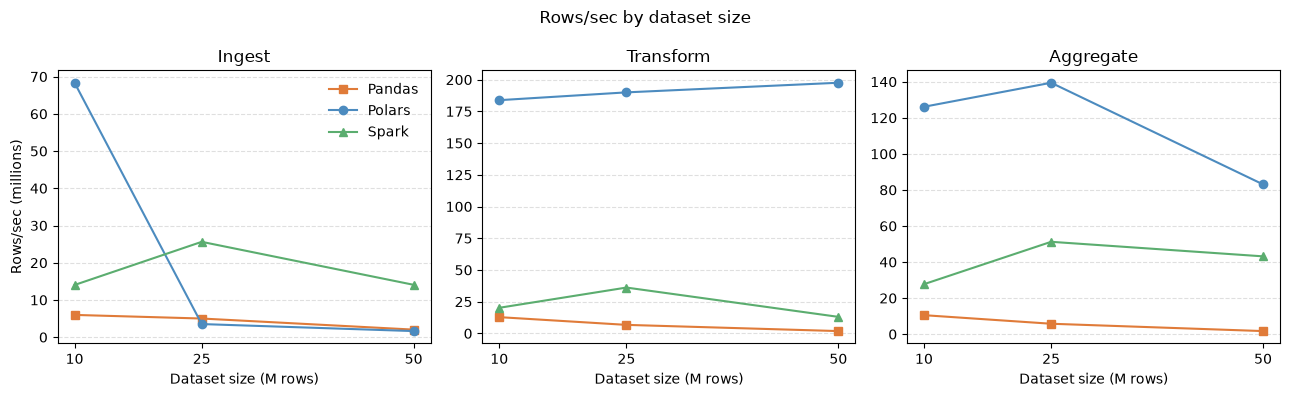

In [2]:

benchmarks = ["Ingest", "Transform", "Aggregate"]
colors  = {"Polars": "#4C8BBF", "Pandas": "#E07B39", "Spark": "#5BAD6F"}
markers = {"Polars": "o",       "Pandas": "s",        "Spark": "^"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
fig.suptitle("Rows/sec by dataset size")

for ax, bench in zip(axes, benchmarks):
    subset = df[df["benchmark"] == bench]
    for fw, grp in subset.groupby("framework"):
        grp = grp.sort_values("size_m")
        ax.plot(grp["size_m"], grp["rows_per_sec"] / 1e6,
                label=fw, color=colors[fw], marker=markers[fw])
    ax.set_title(bench)
    ax.set_xlabel("Dataset size (M rows)")
    ax.set_xticks([10, 25, 50])
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Rows/sec (millions)")
axes[0].legend(frameon=False)
plt.tight_layout()